# Held-out results: one-day-ahead predictive scores

**Held-out test**
- Fit on the history before a block, freeze the parameters, then score the next 63 days one day ahead
- Predictive density of day $t$:

$$p(x_t \mid x_{1:t-1}) = \sum_k \pi_{t|t-1}(k)\, b_k(x_t)$$

- $b_k$: emission density of state $k$; $\pi_{t|t-1}$: state belief before seeing $x_t$
- Belief update: $\pi_{t|t}(k) \propto \pi_{t|t-1}(k)\, b_k(x_t)$, then $\pi_{t+1|t} = \pi_{t|t} A$
- Score: mean of $\log p(x_t \mid x_{1:t-1})$ over test days (higher is better)
- Persistence: $A_{kk}$, expected stay $1/(1-A_{kk})$ days
- Overfitting: training score rises while held-out score does not

**Setup**
- Data: S&P 500 index price, test blocks 2004-01-02 → 2025-12-30
- Features: price-only → standardize → 95% PCA, both fitted on training history only
- Protocol: 10-year start window, then expanding; refit every 63 days; compare only on identical dates

**Models**
- **GMM (M=2…5)**: full covariance, EM, seed 0 (`run_heldout.py`)
- **Flow**: spline flow, best of 5 seeds by training likelihood (`--engine flow`)
- **Baseline** for paired plots: `gmm3_pca`

PCA size changes between folds: only paired same-date differences are comparable.
Scores describe the feature vector, not trading profit.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RESULTS = ROOT / "notebooks/sp500/results"
RUNS = ["heldout_gmm_2004_2025", "heldout_flow_2004_2025"]
BASELINE = "gmm3_pca"


def read(name, **kwargs):
    """Concatenate one CSV name over all result folders that have it."""
    frames = [pd.read_csv(RESULTS / run / f"{name}.csv", **kwargs)
              for run in RUNS if (RESULTS / run / f"{name}.csv").exists()]
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


for run in RUNS:
    if not (RESULTS / run / "daily_scores.csv").exists():
        print(f"Missing {run}: run run_heldout.py --output {RESULTS / run}")
daily = read("daily_scores", parse_dates=["date", "train_end"])
folds = read("fold_scores", parse_dates=["train_end", "test_start", "test_end"])
daily, folds = daily[daily.pca], folds[folds.pca]
assert not daily.duplicated(["date", "spec"]).any()
assert np.isfinite(daily["log_predictive"]).all()
assert (daily["train_end"] < daily["date"]).all()
wide = daily.pivot(index="date", columns="spec", values="log_predictive").sort_index()
print(f"{wide.shape[1]} models; dropping {int(wide.isna().any(axis=1).sum())} "
      f"dates not scored by all")
wide = wide.dropna()
print(f"{wide.index.min().date()} → {wide.index.max().date()}, {len(wide)} days")

Missing heldout_flow_2004_2025: run run_heldout.py --output /home/bomb/project/FlexibleEmissionHMM/notebooks/sp500/results/heldout_flow_2004_2025
4 models; dropping 0 dates not scored by all
2004-01-02 → 2025-12-30, 5534 days


## Scores by model

In [2]:
daily_common = daily[daily.date.isin(wide.index)]
summary = daily_common.groupby("spec").agg(
    days=("log_predictive", "size"), mean_test=("log_predictive", "mean"),
    total_test=("log_predictive", "sum"))
fit = folds.groupby("spec").agg(
    folds=("fold", "size"), converged=("converged", "mean"),
    mean_iterations=("iterations", "mean"))
display(summary.join(fit).round(4))

,days,mean_test,total_test,folds,converged,mean_iterations
spec,,,,,,
gmm2_pca,5534,-6.9946,-38708.1939,88,0.9318,53.9432
gmm3_pca,5534,-6.2696,-34696.1738,88,0.9545,55.7727
gmm4_pca,5534,-6.3809,-35311.6952,88,0.9091,63.8068
gmm5_pca,5534,-6.2598,-34641.5660,88,0.8750,66.9432


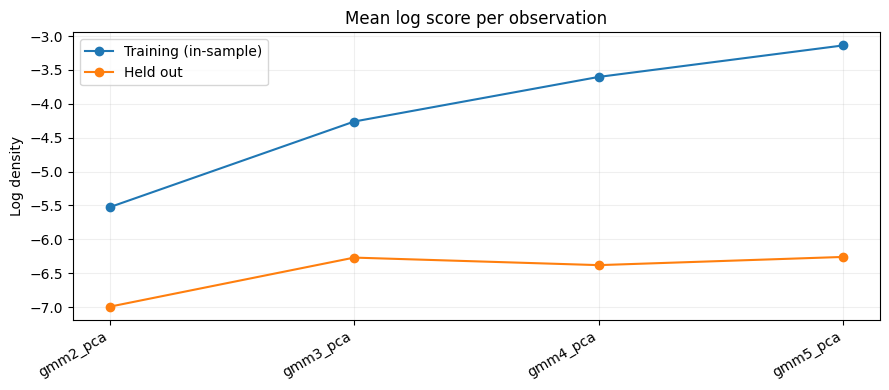

In [3]:
rows = []
for spec, branch in folds.groupby("spec"):
    rows.append({"spec": spec,
                 "train": np.average(branch.train_mean_log_score, weights=branch.training_days),
                 "test": np.average(branch.test_mean_log_score, weights=branch.test_days)})
table = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(table))
ax.plot(x, table.train, "o-", label="Training (in-sample)")
ax.plot(x, table.test, "o-", label="Held out")
ax.set_xticks(x, table.spec, rotation=30, ha="right")
ax.set(title="Mean log score per observation", ylabel="Log density")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Paired differences vs baseline

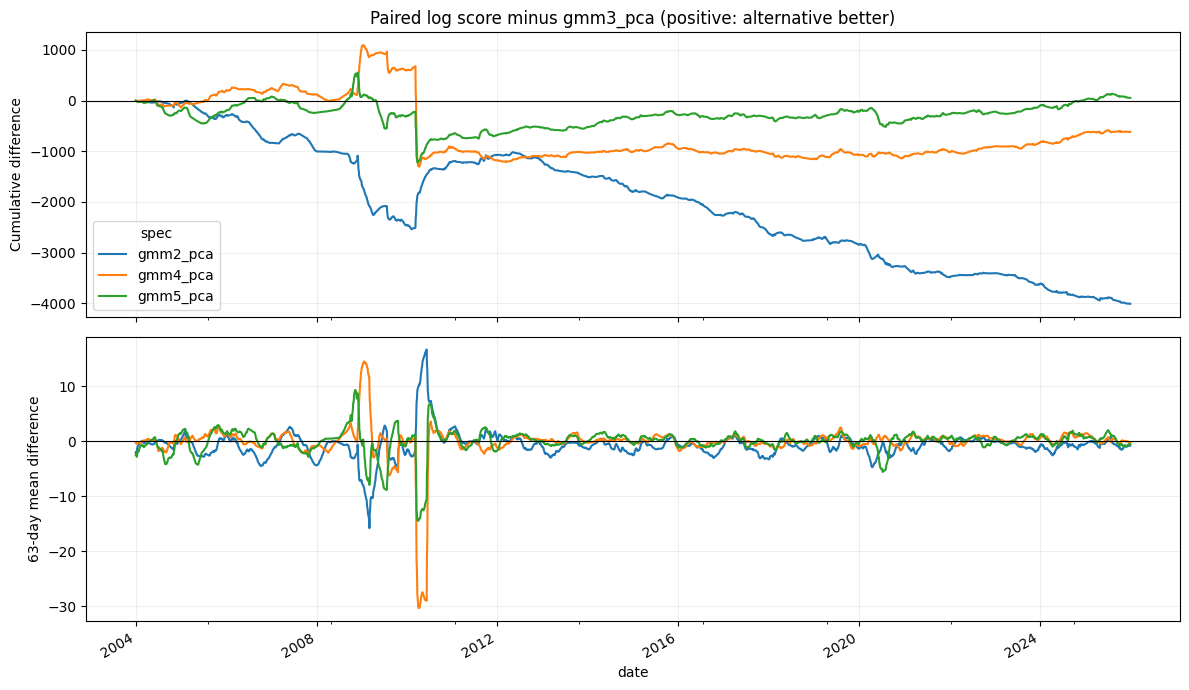

,mean_daily_difference,total_difference,fraction_blocks_better
spec,,,
gmm2_pca,-0.7250,-4012.0201,0.3068
gmm4_pca,-0.1112,-615.5214,0.5455
gmm5_pca,0.0099,54.6078,0.6136


In [4]:
if BASELINE not in wide:
    raise ValueError(f"Missing baseline {BASELINE}")
differences = wide.subtract(wide[BASELINE], axis=0).drop(columns=BASELINE)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
differences.cumsum().plot(ax=axes[0])
differences.rolling(63, min_periods=1).mean().plot(ax=axes[1], legend=False)
axes[0].set(title=f"Paired log score minus {BASELINE} (positive: alternative better)",
            ylabel="Cumulative difference")
axes[1].set(ylabel="63-day mean difference")
for ax in axes:
    ax.axhline(0, color="black", linewidth=0.8)
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
blocks = folds.pivot(index="fold", columns="spec", values="test_mean_log_score")
display(pd.DataFrame({
    "mean_daily_difference": differences.mean(),
    "total_difference": differences.sum(),
    "fraction_blocks_better": (blocks.drop(columns=BASELINE)
                               .sub(blocks[BASELINE], axis=0) > 0).mean(),
}).round(4))

## Flow diagnostics

In [5]:
flow = folds[folds.spec == "flow_pca"]
attempts, regimes = read("seed_attempts"), read("regimes")
if flow.empty:
    print("No flow results yet.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    axes[0].bar(flow.fold, flow.iterations, color=np.where(flow.converged, "C0", "C3"))
    axes[0].set(title="EM iterations (red: not converged)", xlabel="Fold")
    axes[1].bar(flow.fold, flow.seconds / 60, color="C4")
    axes[1].set(title="Fit time (minutes)", xlabel="Fold")
    spread = attempts.groupby("fold").train_log_likelihood.agg(lambda v: v.max() - v.min())
    axes[2].bar(spread.index, spread.values, color="C1")
    axes[2].set(title="Seed spread of training log-likelihood", xlabel="Fold")
    for ax in axes:
        ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()
    ordered = regimes.sort_values(["fold", "volatility"]).copy()
    ordered["rank"] = ordered.groupby("fold").cumcount()
    ordered["test_start"] = ordered.fold.map(flow.set_index("fold").test_start)
    panels = [("volatility", "Daily volatility (%)", 100),
              ("mean_return", "Mean daily return (%)", 100),
              ("persistence", "Self-transition probability", 1),
              ("occupancy", "Occupancy", 1)]
    fig, axes = plt.subplots(len(panels), 1, figsize=(12, 9), sharex=True)
    for ax, (column, label, scale) in zip(axes, panels):
        for rank, group in ordered.groupby("rank"):
            name = "lower-volatility state" if rank == 0 else "higher-volatility state"
            ax.plot(group.test_start, scale * group[column], "o-", ms=3, label=name)
        ax.set_ylabel(label)
        ax.grid(alpha=0.2)
    axes[0].legend()
    axes[0].set_title("Training-window regimes at each refit (sorted by volatility)")
    fig.tight_layout()
    plt.show()

No flow results yet.


## Fold table

In [6]:
display(folds[["fold", "spec", "test_start", "test_end", "training_days", "test_days",
               "n_features", "train_mean_log_score", "test_mean_log_score",
               "converged", "iterations"]].round(4))

,fold,spec,test_start,test_end,training_days,test_days,n_features,train_mean_log_score,test_mean_log_score,converged,iterations
0,0,gmm2_pca,2004-01-02,2004-04-01,2519,63,11,-5.9568,-5.5642,True,57
1,0,gmm3_pca,2004-01-02,2004-04-01,2519,63,11,-6.0981,-5.1570,True,26
2,0,gmm4_pca,2004-01-02,2004-04-01,2519,63,11,-4.9038,-4.8275,True,44
3,0,gmm5_pca,2004-01-02,2004-04-01,2519,63,11,-3.4919,-5.7448,True,61
4,1,gmm2_pca,2004-04-02,2004-07-02,2582,63,11,-5.8865,-3.7608,True,75
...,...,...,...,...,...,...,...,...,...,...,...
347,86,gmm5_pca,2025-07-17,2025-10-14,7937,63,11,-2.7089,-6.6818,True,60
348,87,gmm2_pca,2025-10-15,2025-12-30,8000,53,11,-4.4110,-1.9082,True,64
349,87,gmm3_pca,2025-10-15,2025-12-30,8000,53,11,-3.4316,-1.4437,True,45
350,87,gmm4_pca,2025-10-15,2025-12-30,8000,53,11,-3.2520,-1.4452,True,38
